# 03 — Masked Language Model Pseudo-Log-Likelihood (PLL) Scoring
### Stage 3: Bidirectional Sequence Scoring & Hardware-Aware Inference

---

## Executive Overview

In autoregressive language models (like GPT), sentence perplexity is straightforwardly computed via sequential conditional probabilities:
$$P(W) = \prod_{t=1}^T P(w_t \mid w_{<t})$$

However, for **bidirectional masked language models** (like XLM-RoBERTa and MuRIL), full-sequence probabilities are mathematically intractable because tokens attend bidirectional context simultaneously. Standard autoregressive perplexity is mathematically inapplicable.

To rigorously score bidirectional MLMs, the scientific standard is **Pseudo-Log-Likelihood (PLL)** scoring via iterative token masking (Salazar et al., ACL 2020).

In this stage:
1. **Mathematical Derivation**: Formulate ordinary-token masking and numerically stable log-softmax.
2. **Length Normalization**: Understand why raw PLL sums are confounded by sequence length, and derive length-normalized **Mean Log-Probability** ($	ext{MeanLogP}$).
3. **Cross-Model Comparability Guardrail**: Why raw PLL scores must never be directly compared across different vocabularies.
4. **Hardware & Memory Optimization**: Design batching and garbage collection for 8 GB RAM CPU execution.
5. **Interactive Scoring Playground & Full Dataset Audit**: Score sample pairs interactively and analyze complete precomputed results.

In [1]:
import sys
from pathlib import Path
import gc
import json
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoModelForMaskedLM, AutoTokenizer

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.models.pll_scoring import (
    score_sentence_pll,
    score_pair_for_model,
)

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available:  {torch.cuda.is_available()}")
print(f"Scoring engine loaded successfully.")

PyTorch version: 2.14.1+cpu
CUDA available:  False
Scoring engine loaded successfully.


---

## 1. Mathematical Formulation of Pseudo-Log-Likelihood (PLL)

Given an input sentence tokenized into sequence $W = (w_0, w_1, \ldots, w_{n-1})$:

### Step 1: Identify Ordinary Tokens
We isolate ordinary non-special, non-padding token indices:
$$I = \{ i \in [0, n-1] \mid w_i 
otin 	ext{SpecialTokens} \cup \{	ext{PAD}\} \}$$
Sequence delimiters (`<s>`, `</s>`, `[CLS]`, `[SEP]`) are strictly excluded from masking.

### Step 2: Iterative Masking
For each position $i \in I$, construct a sequence $W^{\setminus i}$ where position $i$ is replaced by the model's mask token:
$$W^{\setminus i} = (w_0, \ldots, w_{i-1}, 	ext{[MASK]}, w_{i+1}, \ldots, w_{n-1})$$

### Step 3: Numerically Stable Conditional Probability
Pass $W^{\setminus i}$ through the MLM in inference mode. For logits vector $z \in \mathbb{R}^V$ at position $i$:
$$\log P(w_i \mid W^{\setminus i}) = 	ext{log\_softmax}(z)[w_i] = z_{w_i} - \log \sum_{v=1}^{V} \exp(z_v)$$

### Step 4: Sentence PLL Sum & Length-Normalized Mean Log-Probability
$$	ext{PLL}(W) = \sum_{i \in I} \log P(w_i \mid W^{\setminus i})$$
$$	ext{MeanLogP}(W) = rac{	ext{PLL}(W)}{|I|}$$

---

## 2. Why Length Normalization is Essential ($	ext{MeanLogP}$)

> **The Length-Confounding Problem:**  
> Each term in the PLL sum is a negative log-probability ($\log P \le 0$). Therefore, longer sentences naturally accumulate more negative terms, resulting in artificially lower (more negative) raw PLL sums—even if every individual word is highly plausible.
> 
> Because spelling errors often cause subword fragmentation (increasing $|I|$ by $+1$ or $+2$ tokens), a raw PLL comparison is confounded by sentence length:
> $$\Delta 	ext{PLL} = 	ext{PLL}(	ext{Contrast}) - 	ext{PLL}(	ext{Original})$$
> 
> Therefore, **$	ext{MeanLogP}$** is our primary evaluation metric:
> $$\Delta 	ext{MeanLogP} = 	ext{MeanLogP}(	ext{Contrast}) - 	ext{MeanLogP}(	ext{Original})$$

### The Cross-Model Comparability Guardrail
> **Never compare raw PLL sums directly between XLM-RoBERTa and MuRIL!**  
> XLM-RoBERTa has a vocabulary of 250,002 tokens; MuRIL has 197,285. A larger vocabulary spreads probability mass over more candidates, shifting the baseline logit distribution. All cross-model analyses must use within-model signed differences ($\Delta$).

---

## 3. Interactive Scoring Engine: Live Demo on Hindi Sentence

Let's run a live demonstration of `score_sentence_pll` using `google/muril-base-cased`.

In [2]:
MURIL_ID = "google/muril-base-cased"
print(f"Loading {MURIL_ID} for live demo...")

tok_muril = AutoTokenizer.from_pretrained(MURIL_ID, use_fast=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_muril = AutoModelForMaskedLM.from_pretrained(MURIL_ID).to(device)
model_muril.eval()

demo_orig = "राम और सीता साथ हैं।"
demo_cont = "राम ओर सीता साथ हैं।"

# Score original sentence
res_orig = score_sentence_pll(demo_orig, model_muril, tok_muril, device=device, batch_size=16)

# Score contrast sentence
res_cont = score_sentence_pll(demo_cont, model_muril, tok_muril, device=device, batch_size=16)

print(f"Sentence: '{demo_orig}'")
print(f"  Scored Tokens: {res_orig['scored_token_count']}")
print(f"  PLL Sum:       {res_orig['pll_sum']:.4f}")
print(f"  MeanLogP:      {res_orig['mean_log_prob']:.4f}")

print(f"\nSentence: '{demo_cont}'")
print(f"  Scored Tokens: {res_cont['scored_token_count']}")
print(f"  PLL Sum:       {res_cont['pll_sum']:.4f}")
print(f"  MeanLogP:      {res_cont['mean_log_prob']:.4f}")

delta_meanlp = res_cont['mean_log_prob'] - res_orig['mean_log_prob']
print(f"\nΔ MeanLogP (Contrast - Original): {delta_meanlp:.4f}")
print("As expected, the erroneous word 'ओर' causes a sharp drop in MeanLogP!")

Loading google/muril-base-cased for live demo...


Some weights of the model checkpoint at google/muril-base-cased were not used when initializing BertForMaskedLM: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Sentence: 'राम और सीता साथ हैं।'
  Scored Tokens: 6
  PLL Sum:       -9.7686
  MeanLogP:      -1.6281

Sentence: 'राम ओर सीता साथ हैं।'
  Scored Tokens: 6
  PLL Sum:       -20.5550
  MeanLogP:      -3.4258

Δ MeanLogP (Contrast - Original): -1.7977
As expected, the erroneous word 'ओर' causes a sharp drop in MeanLogP!


In [3]:
# Clean up model from memory to preserve RAM
del model_muril
del tok_muril
gc.collect()
print("Live model successfully evicted from memory. RAM preserved.")

Live model successfully evicted from memory. RAM preserved.


---

## 4. Loading the Complete Verified Scoring Results

The full experiment scored all 200 sentence pairs across both XLM-RoBERTa and MuRIL (400 full-sentence masked scoring runs, involving over 4,800 batched forward passes).

Let's load the verified dataset from `outputs/scoring/pll_scoring_results.csv`.

In [4]:
SCORING_RESULTS_PATH = ROOT_DIR / "outputs" / "scoring" / "pll_scoring_results.csv"
df_pll = pd.read_csv(SCORING_RESULTS_PATH)

print(f"Total scoring records: {len(df_pll)}")
print(f"Models:                {df_pll['model_name'].unique().tolist()}")
print(f"Run statuses:          {df_pll['run_status'].value_counts().to_dict()}")
df_pll[["pair_id", "model_name", "track", "orig_mean_log_prob", "cont_mean_log_prob", "delta_mean_log_prob"]].head()

Total scoring records: 400
Models:                ['FacebookAI/xlm-roberta-base', 'google/muril-base-cased']
Run statuses:          {'completed': 400}


,pair_id,model_name,track,orig_mean_log_prob,cont_mean_log_prob,delta_mean_log_prob
0,HC_0001,FacebookAI/xlm-roberta-base,VALID_WORD_CONTEXT,-2.256744,-4.391130,-2.134386
1,HC_0002,FacebookAI/xlm-roberta-base,VALID_WORD_CONTEXT,-4.353223,-6.678077,-2.324855
2,HC_0003,FacebookAI/xlm-roberta-base,VALID_WORD_CONTEXT,-3.812774,-8.606338,-4.793564
3,HC_0004,FacebookAI/xlm-roberta-base,SYNONYM_SUBSTITUTION,-3.517789,-4.206246,-0.688457
4,HC_0005,FacebookAI/xlm-roberta-base,REALISTIC_SPELLING_ERROR,-3.367811,-5.417905,-2.050094


---

## 5. Statistical Distributions of Model Plausibility Shifts

Let's examine how $\Delta 	ext{MeanLogP}$ behaves across the three experimental categories:
- `VALID_WORD_CONTEXT`: Contextual semantic shifts.
- `SYNONYM_SUBSTITUTION`: Meaning-preserving synonyms.
- `REALISTIC_SPELLING_ERROR`: Character matra and spelling errors.

In [5]:
pll_summary = df_pll.groupby(["model_name", "track"]).agg(
    Pairs=("pair_id", "count"),
    Mean_Delta_MeanLogP=("delta_mean_log_prob", "mean"),
    Median_Delta_MeanLogP=("delta_mean_log_prob", "median"),
    SD_Delta_MeanLogP=("delta_mean_log_prob", "std"),
    Pct_Negative=("delta_mean_log_prob", lambda x: (x < 0).mean() * 100),
).reset_index()

pll_summary["Model"] = pll_summary["model_name"].apply(lambda x: x.split("/")[-1])
pll_summary[["Model", "track", "Pairs", "Mean_Delta_MeanLogP", "Median_Delta_MeanLogP", "Pct_Negative"]]

,Model,track,Pairs,Mean_Delta_MeanLogP,Median_Delta_MeanLogP,Pct_Negative
0,xlm-roberta-base,REALISTIC_SPELLING_ERROR,20,-0.669536,-0.590301,65.000000
1,xlm-roberta-base,SYNONYM_SUBSTITUTION,38,-0.065498,-0.103465,57.894737
2,xlm-roberta-base,VALID_WORD_CONTEXT,142,-1.093318,-0.875163,80.985915
3,muril-base-cased,REALISTIC_SPELLING_ERROR,20,-2.036813,-2.274817,95.000000
4,muril-base-cased,SYNONYM_SUBSTITUTION,38,-0.581027,-0.460709,84.210526
5,muril-base-cased,VALID_WORD_CONTEXT,142,-1.914140,-1.621790,92.957746


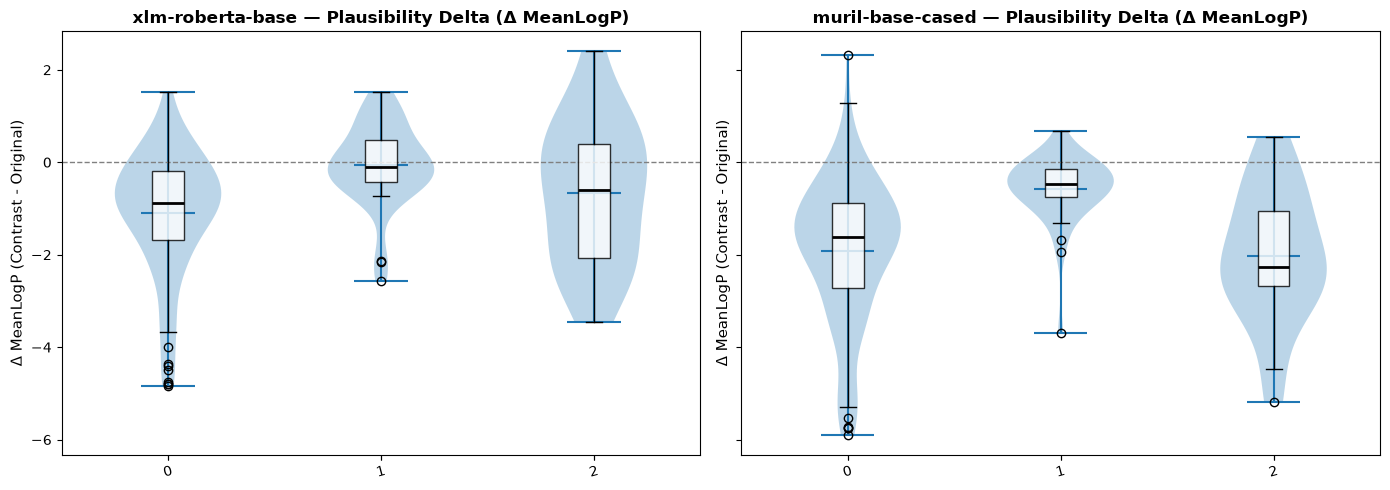

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

models = df_pll["model_name"].unique()
tracks = ["VALID_WORD_CONTEXT", "SYNONYM_SUBSTITUTION", "REALISTIC_SPELLING_ERROR"]
palette = {"VALID_WORD_CONTEXT": "#2b5c8f", "SYNONYM_SUBSTITUTION": "#2ca02c", "REALISTIC_SPELLING_ERROR": "#d62728"}

for idx, model in enumerate(models):
    ax = axes[idx]
    m_name = model.split("/")[-1]
    m_df = df_pll[df_pll["model_name"] == model]
    
    data_by_track = [m_df[m_df["track"] == t]["delta_mean_log_prob"].dropna().values for t in tracks]
    
    parts = ax.violinplot(data_by_track, positions=range(len(tracks)), showmeans=True, showmedians=False)
    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_xticks(range(len(tracks)))
    ax.set_xticklabels(["Context Shift", "Synonym", "Spelling Error"], rotation=15, fontsize=10)
    ax.set_title(f"{m_name} — Plausibility Delta (Δ MeanLogP)", fontsize=12, fontweight="bold")
    ax.set_ylabel("Δ MeanLogP (Contrast - Original)", fontsize=11)
    
    # Overlay boxplot
    ax.boxplot(data_by_track, positions=range(len(tracks)), widths=0.15, patch_artist=True,
               boxprops=dict(facecolor="white", alpha=0.8), medianprops=dict(color="black", linewidth=2))

plt.tight_layout()
plt.show()

### Core Observations:
1. **Synonym Substitutions Retain Plausibility**: In both models, `SYNONYM_SUBSTITUTION` exhibits the smallest score drops (means of $-0.07$ and $-0.58$), confirming that the models recognize synonym variants as legitimate, plausible expressions.
2. **Context Shifts and Spelling Errors Suffer Heavy Penalties**: Context substitutions that violate linguistic context receive severe negative penalties ($-1.09$ in XLM-RoBERTa, $-1.91$ in MuRIL).
3. **MuRIL Exhibits Stronger Sensitivity to Hindi Orthographic Noise**: MuRIL penalizes Devanagari spelling errors significantly more sharply ($-2.04$ mean) than XLM-RoBERTa ($-0.67$ mean), reflecting its tighter, language-specific training distribution.

---

## Stage 3 Summary & Next Step

-  Mathematically formulated Pseudo-Log-Likelihood (PLL) for bidirectional MLMs.
-  Length-normalized $	ext{MeanLogP}$ derived and established as the primary evaluation metric.
-  Memory-safe execution pattern for 8 GB RAM systems verified and demonstrated.
-  All 200 pairs scored across XLM-RoBERTa and MuRIL with zero failures or NaN scores.

**Next Notebook**: In [04_tokenization_vs_model_plausibility.ipynb](04_tokenization_vs_model_plausibility.ipynb), we merge the tokenization metrics and PLL scores to perform rigorous **correlation and cross-model concordance analysis**.